In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.conversion_energy.tyndp import (
    build_c2e_name_to_iso2,
    build_tyndp_nuts_mapping,
    build_tyndp_zone_geometries,
    drop_overlapping_zones,
    load_nuts_geodata,
    load_tyndp_country_codes,
    load_tyndp_market_profiles,
    load_tyndp_supply_capacities,
)
from cordex2energy.results.analysis import load_warming_level_periods
from cordex2energy.results.extreme_value import (
    calculate_climatological_baseline,
    compile_and_compare_periods,
    compute_comprehensive_event_metrics,
    compute_continuous_system_metrics,
    compute_evt_thresholds_for_all_zones,
    compute_zone_pair_cooccurrence,
    extract_evt_duration_severity_records,
    resolve_gwl_period_definitions,
    compute_unserved_energy_fraction,
    compute_flexibility_attenuation_metrics,
)
from cordex2energy.results.plotting_extremes import (
    plot_attribution_change_bars,
    plot_attribution_stacked_bars,
    plot_component_anomaly_distributions,
    plot_duration_severity_scaling,
    plot_evt_threshold_heatmap,
    plot_residual_load_kde,
    plot_spaghetti_iqr,
    plot_violin_grid,
    plot_zone_cooccurrence_boxplots,
    plot_zone_cooccurrence_heatmaps,
    resolve_model_periods,
)
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/cordex2energy/share/proj failed


In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_extremes = path_data_processed / "extremes"
path_data_energy = path_data_processed / "energy"
path_data_energy_europe = path_data_energy / "europe"
path_c2e = path_data_processed / "c2e" / "outputs"
path_tyndp = path_data_extremes / "tyndp"
path_residual_load = path_data_extremes / "residual_load"

# Load data

In [4]:
climate_scenario = "rcp85"
demand_scenario = "DE"
demand_year = 2050  # int — 2019 for REF, 2040/2050 for GA/DE
supply_scenario = "HIGH"
supply_year = 2040  # int — 2030/2040/2050
rolling_window_residual_load = 1
use_reservoir_hydro = True
use_batteries = True
use_prosumer_batteries = True

# Scenario suffix as used by compute_tyndp_projections_extremes.py
# Pattern: {demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}
run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"
if rolling_window_residual_load and rolling_window_residual_load > 1:
    run_tag += f"_rlsmooth_{rolling_window_residual_load}"
if use_reservoir_hydro:
    run_tag += "_reservoirdispatch"
if use_batteries:
    run_tag += "_batteries"
    if use_prosumer_batteries:
        run_tag += "_prosumer"

# ── Period definition toggle ──────────────────────────────────────────────────
# USE_WARMING_LEVELS = False  → fixed calendar periods (Reference / Mid-Century / End-Century)
# USE_WARMING_LEVELS = True   → 20-year windows centred on Global Warming Level crossings
#                               derived from the driving CMIP5 GCM for each model chain.
#                               WARMING_LEVELS lists which GWLs to include (°C above 1850–1900).
USE_WARMING_LEVELS = True
WARMING_LEVELS = [1.5, 2.0, 3.0]

## TYNDP

In [5]:
# ── Load TYNDP supply capacities ──────────────────────────────────────────────

print("\n── Loading TYNDP supply capacities ──────────────────────────────────────────")
path_supply_excel = (
    path_tyndp / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx"
)
df_tyndp_solar, df_tyndp_wind_onshore, df_tyndp_wind_offshore = (
    load_tyndp_supply_capacities(path_supply_excel)
)
print(f"  Solar:           {len(df_tyndp_solar)} rows")
print(f"  Onshore wind:    {len(df_tyndp_wind_onshore)} rows")
print(f"  Offshore wind:   {len(df_tyndp_wind_offshore)} rows")


── Loading TYNDP supply capacities ──────────────────────────────────────────
  Solar:           57 rows
  Onshore wind:    57 rows
  Offshore wind:   68 rows


In [6]:
# ── Load TYNDP demand metadata and build country code mapping ─────────────────

print("\n── Building country code mapping ────────────────────────────────────────────")
path_demand_excel = (
    path_tyndp / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb"
)
tyndp_country_codes = load_tyndp_country_codes(path_demand_excel)
C2E_NAME_TO_ISO2 = build_c2e_name_to_iso2(tyndp_country_codes)
print(f"  {len(tyndp_country_codes)} countries in TYNDP mapping.")


── Building country code mapping ────────────────────────────────────────────
  35 countries in TYNDP mapping.


In [7]:
# ── Load TYNDP demand scenario table ──────────────────────────────────────────

print("\n── Loading TYNDP demand scenario table ──────────────────────────────────────")
df_tyndp_demand = pd.read_excel(
    path_demand_excel,
    sheet_name="3_DEMAND_OUTPUT",
    header=[0, 1],
)
df_tyndp_demand.columns = [
    f"{l2}_{l1}" if str(l2) in ["2019", "2040", "2050"] else l2
    for l1, l2 in df_tyndp_demand.columns
]


── Loading TYNDP demand scenario table ──────────────────────────────────────


In [8]:
# # ── Build TYNDP zone → NUTS mapping and zone geometries ───────────────────────

# print("\n── Building TYNDP zone geometries ───────────────────────────────────────────")
# tyndp_bidding_zones = (
#     df_tyndp_solar[["Country"]]
#     .copy()
#     .rename(columns={"Country": "Bidding Zone"})
#     .iloc[:-3]
# )
# tyndp_bidding_zones["iso2"] = tyndp_bidding_zones["Bidding Zone"].apply(
#     lambda x: str(x)[:2]
# )
# all_zones = sorted(tyndp_bidding_zones["Bidding Zone"].unique())

# gdf_nuts1, gdf_nuts2, gdf_uk_nuts1 = load_nuts_geodata(
#     path_data_processed / "maps" / "nuts"
# )
# tyndp_nuts2_mapping, df_tyndp_nuts_mapping = build_tyndp_nuts_mapping(
#     all_zones, gdf_nuts2, gdf_uk_nuts1
# )
# gdf_tyndp_zones = build_tyndp_zone_geometries(
#     tyndp_nuts2_mapping, df_tyndp_nuts_mapping, gdf_nuts2, gdf_uk_nuts1
# )
# gdf_tyndp_zones = drop_overlapping_zones(gdf_tyndp_zones)
# print(f"  {len(gdf_tyndp_zones)} zones after dropping overlapping geometries.")

In [9]:
# path_demand_profiles_dir = path_tyndp / "Demand Profiles"
# ds_market_for_targets, ds_prosumer_for_targets = load_tyndp_market_profiles(
#     path_demand_profiles_dir, demand_scenario, demand_year
# )

In [10]:
ds_baseload = xr.open_dataset(
    path_tyndp / "baseload" / f"baseload_{demand_scenario}_{demand_year}.nc"
)

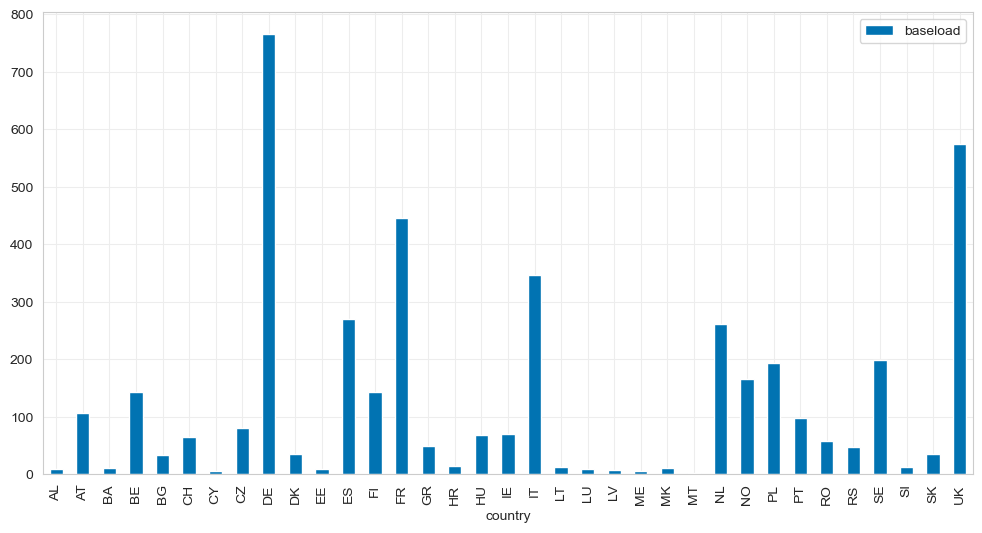

In [11]:
(ds_baseload.sum(dim="hour_of_year").baseload.to_dataframe() * 1e-3).plot(
    kind="bar", figsize=(12, 6)
)
plt.show()

## Residual load and components

In [12]:
ds_residual_load = []
ds_residual_load_zonal = []
ds_components = []
ds_components_zonal = []

for folder in sorted(path_residual_load.glob("*")):
    if not folder.is_dir():
        continue
    run_dir = folder / run_tag
    if not run_dir.exists():
        print(f"  Skipping {folder.name}: no '{run_tag}' subfolder")
        continue
    model_name = "_".join(folder.name.split("_")[:-1])  # strip trailing _rcp85
    print(f"  Loading model '{model_name}' from {run_dir}")
    # ds_residual_load.append(
    #     xr.open_dataset(run_dir / "residual_load.nc").expand_dims(
    #         dim={"model": [model_name]}
    #     )
    # )
    ds_residual_load_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(
            dim={"model": [model_name]}
        )
    )
    # ds_components.append(
    #     xr.open_dataset(run_dir / "components.nc").expand_dims(
    #         dim={"model": [model_name]}
    #     )
    # )
    ds_components_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(
            dim={"model": [model_name]}
        )
    )

# ds_residual_load = xr.concat(ds_residual_load, dim="model", join="outer")
ds_residual_load_zonal = xr.concat(ds_residual_load_zonal, dim="model", join="outer")
# ds_components = xr.concat(ds_components, dim="model", join="outer")
ds_components_zonal = xr.concat(ds_components_zonal, dim="model", join="outer")

print(f"Loaded {len(ds_residual_load_zonal.model)} models for run '{run_tag}'")

  Loading model 'CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1' from /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer


  Loading model 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1' from /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1_rcp85/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer
  Loading model 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1' from /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer
  Loading model 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1' from /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer
  Loading model 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1' from /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer
  Loading model 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1' from /net/exo/landclim/yhadda

# Analysis

The analysis follows the same structure as `extremes.ipynb` but applied to **all model chains simultaneously**.

Inter-model variability is represented using:
- **KDE envelopes**: ensemble median KDE (bold line) with the inter-model 10–90th percentile band (shaded).
- **Spaghetti + IQR**: individual model traces (thin, grey) with the ensemble median (thick, coloured) and an IQR band.
- **Violin plots**: full distribution of model values per period, per zone.
- **Attribution heatmap**: change in climate-driver shares across periods and models.


## Setup — constants, palettes and helpers

In [13]:
# ── Season / period constants ─────────────────────────────────────────────────
season_map = {
    3: "MAM",
    4: "MAM",
    5: "MAM",
    6: "JJA",
    7: "JJA",
    8: "JJA",
    9: "SON",
    10: "SON",
    11: "SON",
    12: "DJF",
    1: "DJF",
    2: "DJF",
}
season_order = ["DJF", "MAM", "JJA", "SON"]

period_defs = {
    "Reference": (REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]),
    "Mid-Century": (MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]),
    "End-Century": (END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1]),
}
# Labels used internally by compile_and_compare_periods
PERIOD_LABEL = {
    "Reference": "1_Reference",
    "Mid-Century": "2_Mid-Century",
    "End-Century": "3_End-Century",
}
PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}

period_colors = {
    "Reference": "#4A90E2",
    "Mid-Century": "#F5A623",
    "End-Century": "#E24A4A",
}
period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}

# ── Component / generation palettes ──────────────────────────────────────────
comp_palette = {
    "gen_pv": "#E6AB02",
    "gen_wind_on": "#7570B3",
    "gen_wind_off": "#1B7C3D",
    "gen_hydro_ror": "#3182BD",
    "reservoir_dispatch_gwh": "#08519C",
    "total_demand": "#D95F02",
}
driver_palette = {
    "Demand": "#D95F02",
    "PV": "#E6AB02",
    "Wind Onshore": "#7570B3",
    "Wind Offshore": "#1B7C3D",
    "Hydro RoR": "#3182BD",
    "Reservoir Hydro": "#08519C",
    "Battery": "#8B5A2B",
}
driver_cols = {
    "Demand": "Demand_Driven_Share_%",
    "PV": "PV_Driven_Share_%",
    "Wind Onshore": "Wind_Onshore_Driven_Share_%",
    "Wind Offshore": "Wind_Offshore_Driven_Share_%",
    "Hydro RoR": "Hydro_RoR_Driven_Share_%",
    "Reservoir Hydro": "Reservoir_Hydro_Driven_Share_%",
    "Battery": "Battery_Driven_Share_%",
}

# ── Absolute anomaly GWh columns (for plot_component_anomaly_distributions) ──
anomaly_component_cols = {
    "Demand": "Avg_Demand_Anomaly_GWh",
    "PV": "Avg_PV_Anomaly_GWh",
    "Wind Onshore": "Avg_Wind_Onshore_Anomaly_GWh",
    "Wind Offshore": "Avg_Wind_Offshore_Anomaly_GWh",
    "Hydro RoR": "Avg_Hydro_RoR_Anomaly_GWh",
    "Reservoir Hydro": "Avg_Reservoir_Anomaly_GWh",
    "Battery": "Avg_Battery_Anomaly_GWh",
}

zones = ds_residual_load_zonal["zone"].values
models = ds_residual_load_zonal["model"].values
n_models = len(models)

print(f"Zones   : {zones}")
print(f"Models  : {n_models}  →  {models}")
print(f"Periods : {list(period_defs.keys())}")

Zones   : ['British_Isles' 'Central_Eastern' 'Central_Western' 'Iberian_Peninsula'
 'Nordic' 'South_East']
Models  : 9  →  ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1'
 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1'
 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1'
 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1'
 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1'
 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1'
 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1'
 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1'
 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1']
Periods : ['Reference', 'Mid-Century', 'End-Century']


In [14]:
# ── Global Warming Level period resolution ────────────────────────────────────
# When USE_WARMING_LEVELS=True, overrides period_defs / PERIOD_LABEL / period_colors
# with per-model 20-year windows centred on each GWL crossing.
# Otherwise the fixed calendar periods defined in the cell above remain unchanged.

if USE_WARMING_LEVELS:
    period_defs, PERIOD_LABEL, period_colors = resolve_gwl_period_definitions(
        warming_levels=WARMING_LEVELS,
        models=models,
        chain_meta_path="../../models.json",
        gwl_yaml_path=path_data_processed
        / "cmip5_warming_levels_all_ens_1861_1900.yml",
        climate_scenario=climate_scenario,
    )
    PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}
    period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}

    print(f"Global Warming Level periods (scenario: {climate_scenario}):")
    for label, windows in period_defs.items():
        n_covered = len(windows)
        print(f"  {label}: {n_covered}/{len(models)} models")
        for chain_id, (s, e) in list(windows.items())[:2]:
            print(f"    {chain_id}: {s}-{e}")
        if n_covered > 2:
            print(f"    ... +{n_covered - 2} more")
else:
    print(f"Fixed calendar periods: {list(period_defs.keys())}")

Global Warming Level periods (scenario: rcp85):
  +1.5°C: 9/9 models
    CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1: 2022-2041
    CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1: 2015-2034
    ... +7 more
  +2.0°C: 9/9 models
    CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1: 2036-2055
    CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1: 2027-2046
    ... +7 more
  +3.0°C: 9/9 models
    CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1: 2059-2078
    CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1: 2046-2065
    ... +7 more


## Multi-model KDE by zone

One figure per TYNDP balancing zone showing the full residual load distribution (not split by season).
For each period the **ensemble median KDE** is drawn as a bold line; the **10–90th-percentile band
across models** is shaded. The x-axis is shared across periods so distributional shifts are immediately
visible. For seasonal breakdowns see `extremes_seasonal.ipynb`.

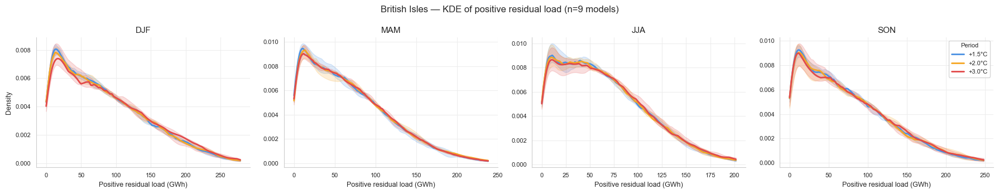

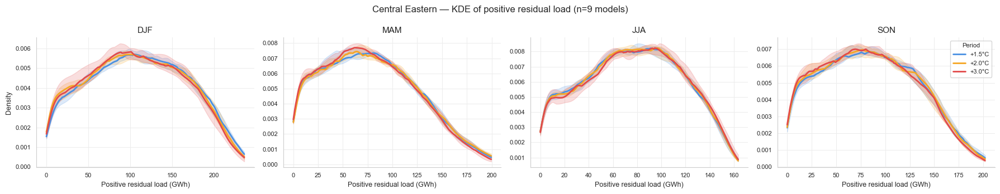

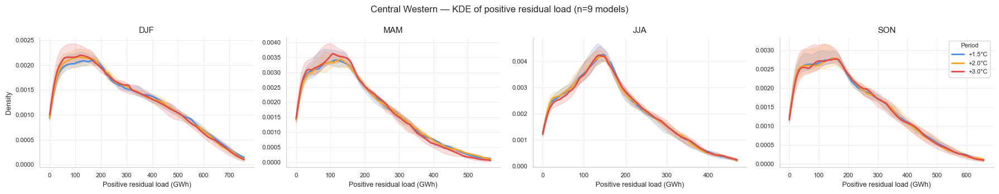

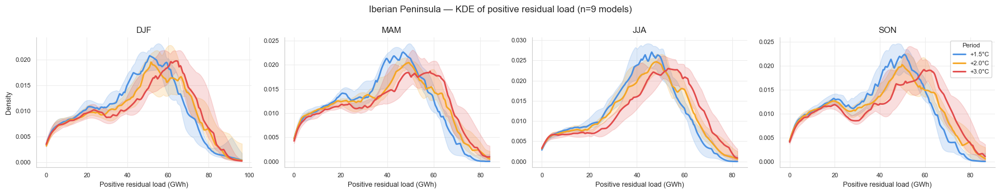

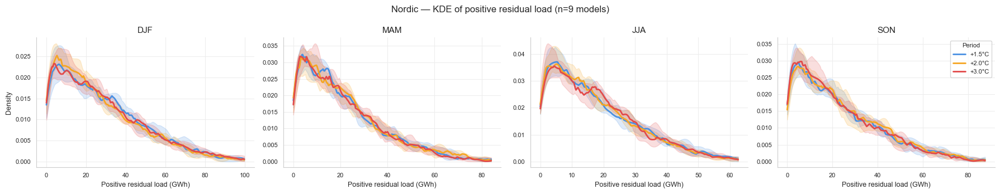

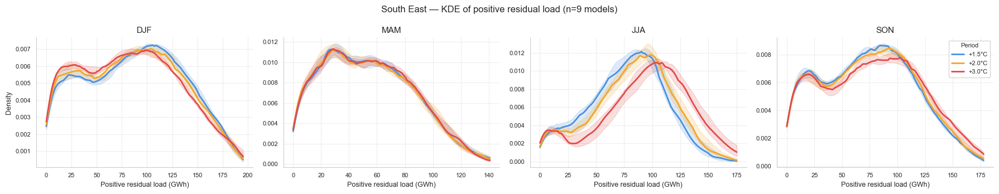

In [15]:
plot_residual_load_kde(
    ds_residual_load_zonal,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    models=models,
    threshold=0,  # None → full distribution; 0.0 → positive RL only
)

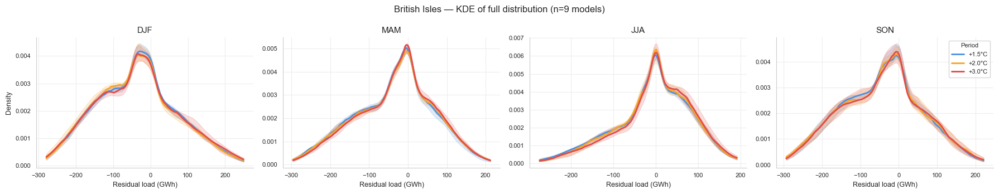

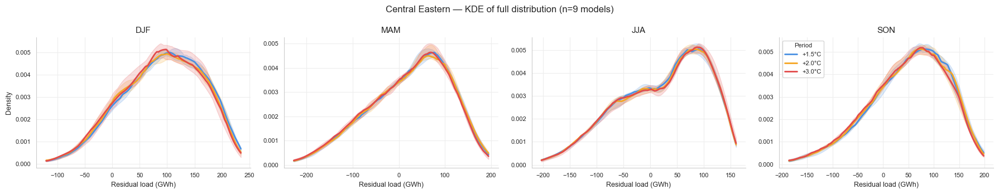

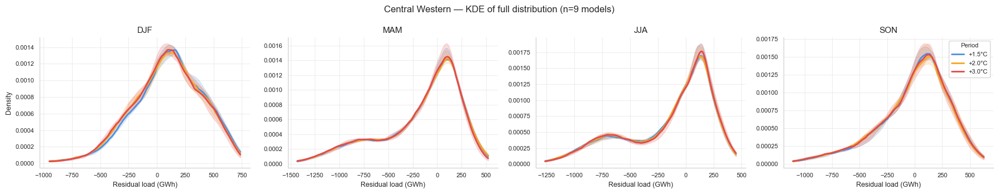

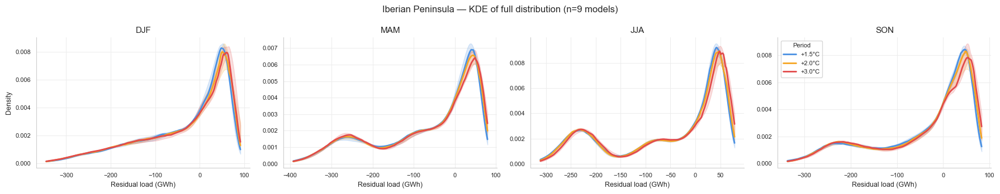

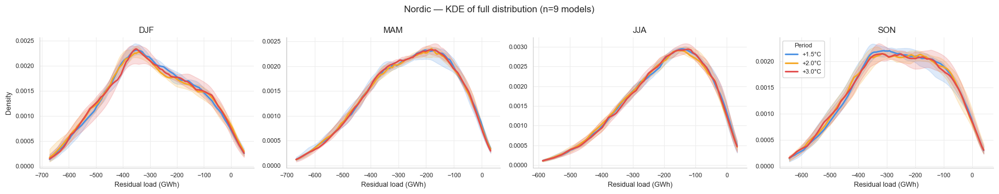

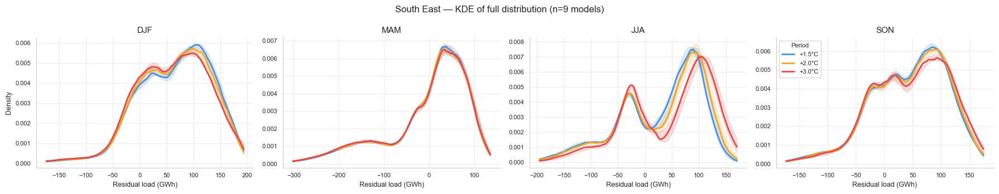

In [16]:
plot_residual_load_kde(
    ds_residual_load_zonal,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    models=models,
    threshold=None,  # None → full distribution including negative RL
)

## Per-model EVT thresholds and event metrics

For each model chain:
1. The **EVT threshold** is calibrated on that model's own reference-period residual load (Peaks-Over-Threshold / GPD stability test).
2. **Continuous system metrics** (ramping, PCIT, climate anomalies) are computed for each period using the full-simulation climatological baseline of that model.
3. **Comprehensive event metrics** are computed with both the zero threshold (baseline analysis) and the EVT threshold (extreme-event analysis).

Calibrating thresholds per model avoids conflating a structural bias (model too high/low) with a genuine change in extreme behaviour.

In [44]:
# ── Per-model EVT threshold calibration and annual event metrics ──────────────

all_df_baseline = []
all_df_extreme = []
evt_thresholds = {}
_cache_rl   = {}  # reused by co-occurrence and duration-severity
_cache_comp = {}  # reused by unserved-energy metric

da_zero_thr = xr.DataArray(np.zeros(len(zones)), coords={"zone": zones}, dims=["zone"])

for model in models:
    print(f"\n── {model} ──────────────────────────────────────────────────────")

    ds_rl_m = (
        ds_residual_load_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    ds_comp_m = (
        ds_components_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    _common_time = np.intersect1d(ds_rl_m.time.values, ds_comp_m.time.values)
    ds_rl_m = ds_rl_m.sel(time=_common_time)
    ds_comp_m = ds_comp_m.sel(time=_common_time)

    print("  Computing climatological baseline ...")
    ds_clim = calculate_climatological_baseline(
        ds_comp_m.sel(time=slice(*REFERENCE_PERIOD))
    )

    t0_ref, t1_ref = REFERENCE_PERIOD
    ds_rl_ref = ds_rl_m.sel(time=slice(t0_ref, t1_ref))
    ds_comp_ref = ds_comp_m.sel(time=slice(t0_ref, t1_ref))
    ds_met_ref = compute_continuous_system_metrics(ds_rl_ref, ds_comp_ref, ds_clim)

    print("  Calibrating EVT thresholds ...")
    da_evt, da_evt_pct = compute_evt_thresholds_for_all_zones(ds_met_ref["residual_load"], p_value_threshold=0.1)
    evt_thresholds[model] = da_evt
    print(
        "  EVT thresholds (GW):",
        {str(z): round(float(da_evt.sel(zone=z)), 1) for z in da_evt.zone.values},
    )
    print(
        "  Percentile of full RL distribution (%):",
        {str(z): round(float(da_evt_pct.sel(zone=z)), 1) for z in da_evt_pct.zone.values},
    )

    resolved_periods = {
        k: v
        for k, v in resolve_model_periods(period_defs, model).items()
        if v is not None
    }

    period_res_baseline = {}
    period_res_extreme = {}

    for period_name, (t0, t1) in resolved_periods.items():
        print(f"  -> {period_name} ({t0}-{t1}) ...")
        ds_rl_p = ds_rl_m.sel(time=slice(t0, t1))
        ds_comp_p = ds_comp_m.sel(time=slice(t0, t1))
        ds_met_p = compute_continuous_system_metrics(ds_rl_p, ds_comp_p, ds_clim)

        period_res_baseline[period_name] = compute_comprehensive_event_metrics(
            ds_met_p, da_zero_thr
        )
        period_res_extreme[period_name] = compute_comprehensive_event_metrics(
            ds_met_p, da_evt
        )

    _period_names = [PERIOD_LABEL[k] for k in resolved_periods]
    df_b, _ = compile_and_compare_periods(
        *[period_res_baseline[k] for k in resolved_periods], period_names=_period_names
    )
    df_e, _ = compile_and_compare_periods(
        *[period_res_extreme[k] for k in resolved_periods], period_names=_period_names
    )
    df_b = df_b.reset_index()
    df_e = df_e.reset_index()
    df_b["model"] = model
    df_e["model"] = model
    all_df_baseline.append(df_b)
    all_df_extreme.append(df_e)
    _cache_rl[model]   = ds_rl_m
    _cache_comp[model] = ds_comp_m

df_ens_baseline = pd.concat(all_df_baseline, ignore_index=True)
df_ens_extreme = pd.concat(all_df_extreme, ignore_index=True)
df_ens_baseline["Period"] = df_ens_baseline["Period"].map(PERIOD_SHORT)
df_ens_extreme["Period"] = df_ens_extreme["Period"].map(PERIOD_SHORT)

print(
    f"\n✓ {df_ens_baseline.shape[0]} rows: "
    f"{n_models} models x {len(zones)} zones x {len(period_defs)} periods"
)
df_ens_extreme.head(6)


── CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 ──────────────────────────────────────────────────────
  Computing climatological baseline ...
  Calibrating EVT thresholds ...
  EVT thresholds (GW): {'British_Isles': 170.8, 'Central_Eastern': 223.2, 'Central_Western': 659.7, 'Iberian_Peninsula': 59.1, 'Nordic': 53.3, 'South_East': 166.3}
  Percentile of full RL distribution (%): {'British_Isles': 98.2, 'Central_Eastern': 99.6, 'Central_Western': 99.5, 'Iberian_Peninsula': 92.5, 'Nordic': 99.8, 'South_East': 98.6}
  -> +1.5°C (2022-2041) ...
  -> +2.0°C (2036-2055) ...
  -> +3.0°C (2059-2078) ...

── CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1 ──────────────────────────────────────────────────────
  Computing climatological baseline ...
  Calibrating EVT thresholds ...
  EVT thresholds (GW): {'British_Isles': 132.7, 'Central_Eastern': 145.5, 'Central_Western': 386.4, 'Iberian_Peninsula': 58.3, 'Nordic': 41.1, 'South_East': 171.5}
  Percentile of full RL distribution (%): {'British_Isles': 94.5,

,Zone,Period,Frequency,Avg_Duration_Hours,Max_Duration_Hours,Max_Peak_Intensity_GW,Max_Upward_Ramp_GW_per_hr,Total_Annual_Energy_Severity_GWh,Avg_Energy_Severity_GWh,Max_Single_Event_Severity_GWh,...,Reservoir_Hydro_Driven_Share_%,Battery_Driven_Share_%,Avg_Demand_Anomaly_GWh,Avg_PV_Anomaly_GWh,Avg_Wind_Onshore_Anomaly_GWh,Avg_Wind_Offshore_Anomaly_GWh,Avg_Hydro_RoR_Anomaly_GWh,Avg_Reservoir_Anomaly_GWh,Avg_Battery_Anomaly_GWh,model
0,British_Isles,+1.5°C,644,5.128882,18.0,313.398122,50.672941,4981.307578,154.698993,1576.776593,...,0.0,2.5,89.84,-8.60,-209.79,-682.82,-0.0,-0.00,-25.73,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
1,British_Isles,+2.0°C,656,5.112805,21.0,318.193506,50.672941,5399.897021,164.631007,1674.704245,...,0.0,2.6,81.83,-8.19,-204.94,-701.24,-0.0,-0.00,-26.76,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
2,British_Isles,+3.0°C,585,4.841026,18.0,316.581135,48.525451,4076.076102,139.353029,1219.275352,...,0.0,2.6,70.57,-11.92,-193.57,-635.19,-0.0,-0.00,-24.33,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
3,Central_Eastern,+1.5°C,89,7.314607,21.0,266.231575,46.257799,303.526770,68.208263,306.962685,...,0.9,0.2,247.60,-4.66,-338.69,-345.56,-0.0,-8.33,-1.70,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
4,Central_Eastern,+2.0°C,66,6.590909,18.0,258.038625,46.257799,196.736657,59.617169,306.962685,...,0.9,0.2,193.88,-4.27,-307.56,-325.60,-0.0,-7.98,-1.56,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
5,Central_Eastern,+3.0°C,27,5.888889,15.0,257.948869,25.843941,68.221460,50.534415,245.486635,...,0.3,0.1,179.94,-4.23,-279.85,-280.00,-0.0,-2.32,-0.89,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1


In [45]:
df_use_raw = compute_unserved_energy_fraction(
    _cache_rl, _cache_comp, period_defs, models, zones
)
df_use_agg = (
    df_use_raw
    .groupby(["model", "period", "zone"])["use_fraction"]
    .agg(Mean_USE_pct="mean", Max_USE_pct="max")
    .reset_index()
)
df_use_agg["Mean_USE_pct"] *= 100
df_use_agg["Max_USE_pct"]  *= 100
df_use_agg = df_use_agg.rename(columns={"period": "Period", "zone": "Zone"})
df_ens_extreme = df_ens_extreme.merge(
    df_use_agg, on=["model", "Period", "Zone"], how="left"
)
print(f"df_ens_extreme: {df_ens_extreme.shape[1]} columns, USE range: "
      f"{df_ens_extreme['Mean_USE_pct'].min():.2f}% – {df_ens_extreme['Mean_USE_pct'].max():.2f}%")


df_ens_extreme: 34 columns, USE range: 0.21% – 34.23%


In [46]:
df_flex = compute_flexibility_attenuation_metrics(
    _cache_rl, _cache_comp, evt_thresholds, period_defs, models, zones
)
df_flex = df_flex.rename(columns={"period": "Period", "zone": "Zone"})
df_ens_extreme = df_ens_extreme.merge(
    df_flex.drop(columns="n_events"),
    on=["model", "Period", "Zone"],
    how="left",
)
print(f"Flexibility attenuation columns added: "
      f"{[c for c in df_ens_extreme.columns if 'attenuation' in c or 'deployed' in c]}")


Flexibility attenuation columns added: ['battery_deployed_gwh_per_event', 'prosumer_deployed_gwh_per_event', 'utility_deployed_gwh_per_event', 'reservoir_deployed_gwh_per_event', 'battery_attenuation_pct', 'prosumer_attenuation_pct', 'utility_attenuation_pct', 'reservoir_attenuation_pct', 'combined_attenuation_pct']


## Ensemble metric evolution — spaghetti + IQR envelope

Each subplot shows one TYNDP balancing zone. Grey lines are individual model chains; the **coloured
line is the ensemble median**; the **shaded band is the inter-quartile range (Q25–Q75)**.
This is the standard IPCC multi-model representation: the central estimate (median) is shown
together with the spread (IQR), making it easy to assess both the signal and the uncertainty.

Four key operational metrics are shown for the baseline (zero-threshold) analysis.

In [47]:
baseline_metrics = [
    ("Frequency", "Event count (whole period)"),
    ("Avg_Duration_Hours", "Mean event duration (h)"),
    ("Avg_Energy_Severity_GWh", "Mean event energy severity (GWh)"),
    ("Total_Annual_Energy_Severity_GWh", "Mean annual unmet energy (GWh)"),
    ("P90_Annual_Energy_Severity_GWh", "P90 annual unmet energy — design year (GWh)"),
    (
        "Std_Annual_Energy_Severity_GWh",
        "Std of annual unmet energy — year-to-year variability (GWh)",
    ),
    (
        "Avg_Net_System_Residual_Load_During_Events_GW",
        "Mean net system residual load during events (GW)",
    ),
    (
        "Max_Net_System_Residual_Load_During_Events_GW",
        "Max net system residual load during events (GW)",
    ),
]

# for metric, ylabel in baseline_metrics:
#     plot_spaghetti_iqr(
#         df_ens_baseline,
#         metric=metric,
#         ylabel=ylabel,
#         title=f"Baseline analysis — {ylabel}\n(zero threshold · {supply_scenario} {supply_year})",
#         period_defs=period_defs,
#         zones=zones,
#         models=models,
#         period_colors=period_colors,
#     )

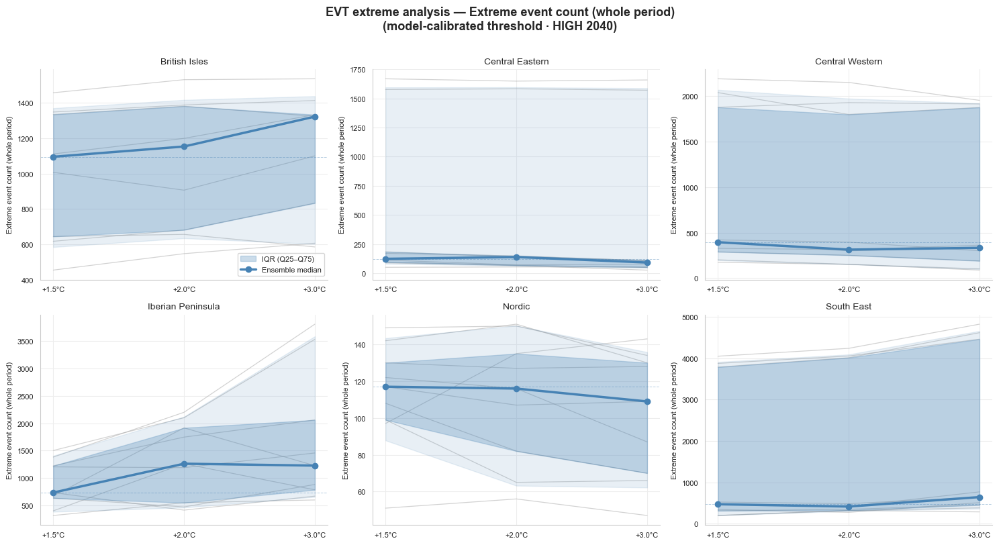

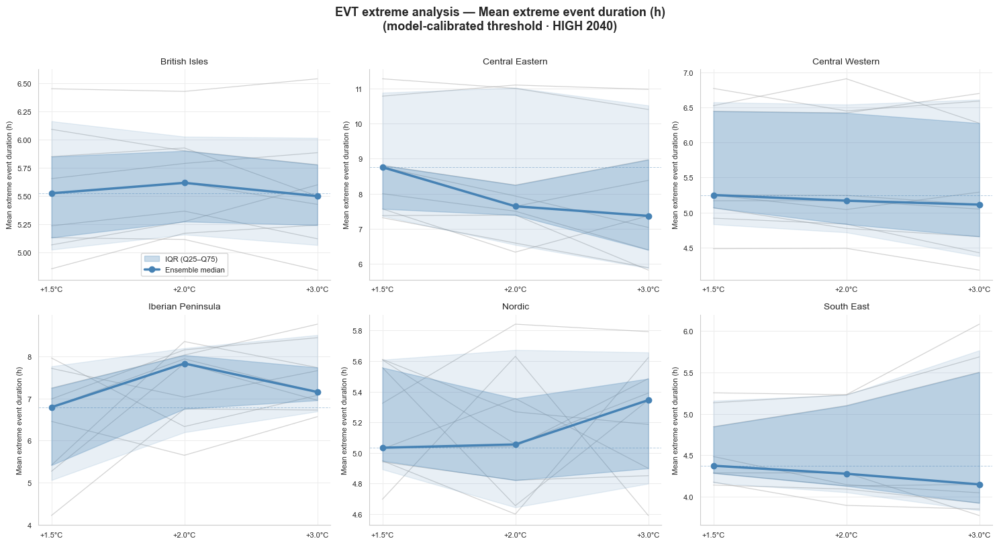

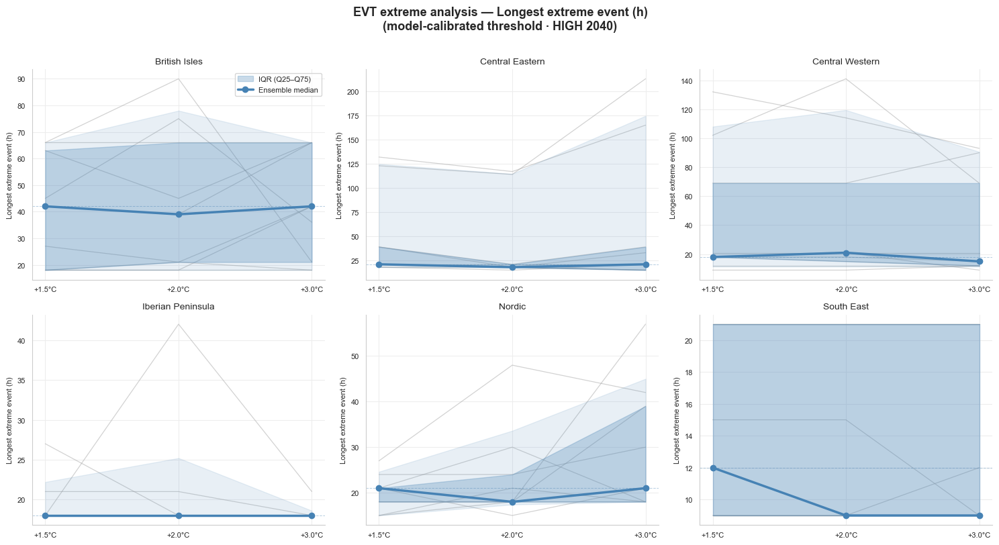

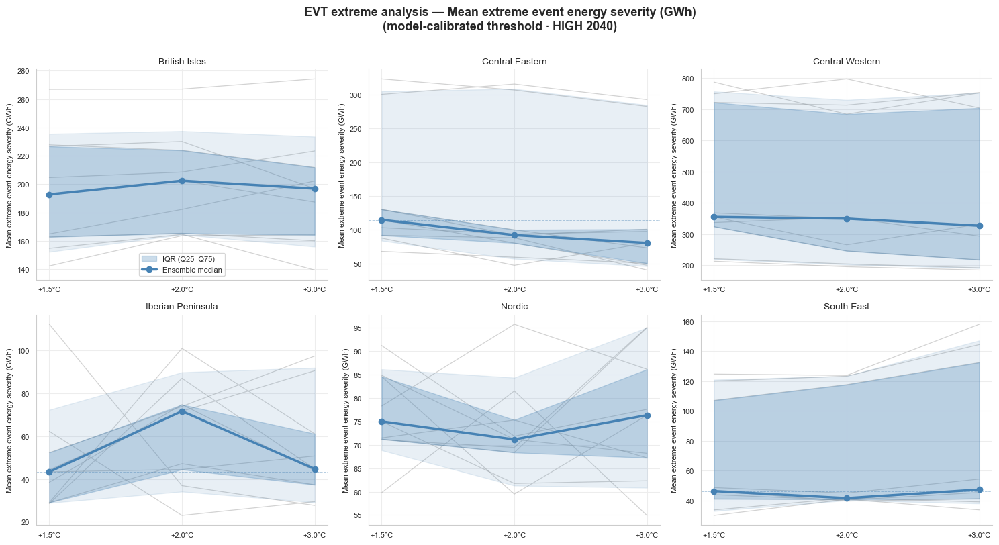

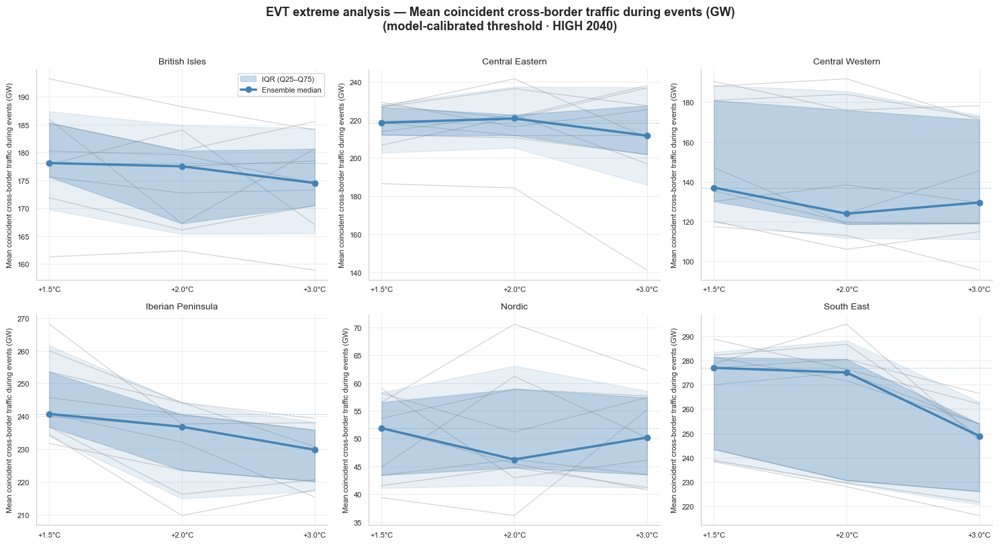

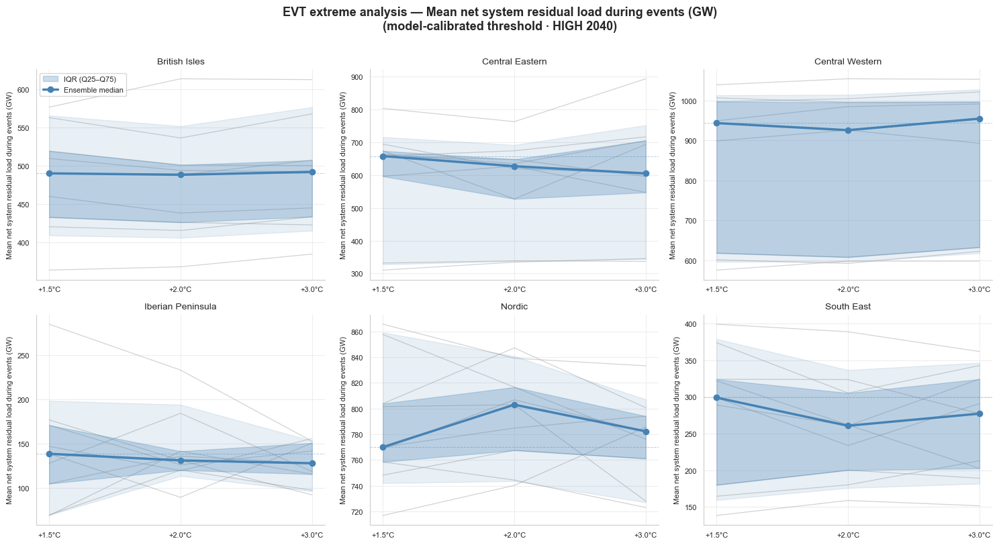

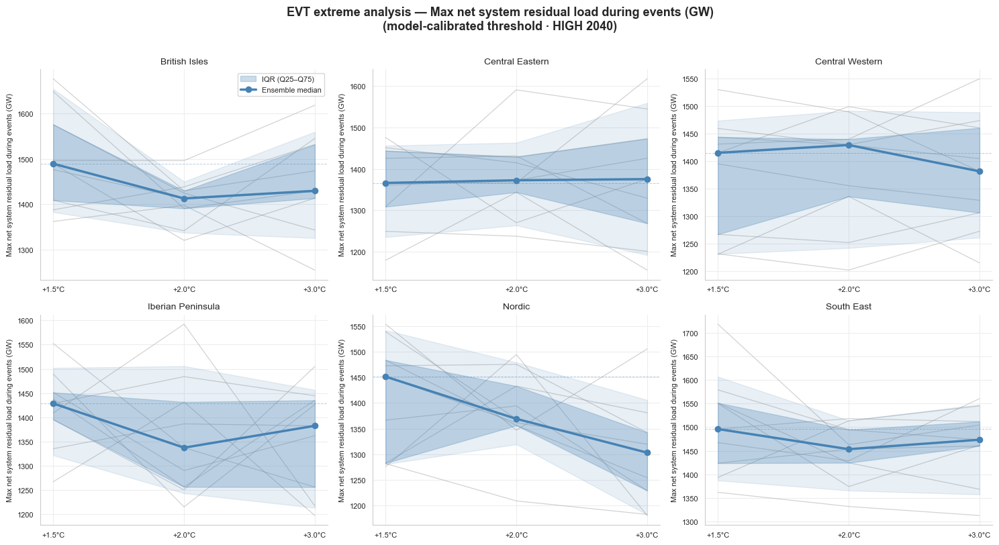

In [48]:
extreme_metrics = [
    ("Frequency", "Extreme event count (whole period)"),
    ("Avg_Duration_Hours", "Mean extreme event duration (h)"),
    ("Max_Duration_Hours", "Longest extreme event (h)"),
    ("Avg_Energy_Severity_GWh", "Mean extreme event energy severity (GWh)"),
    (
        "Avg_PCIT_During_Events_GW",
        "Mean coincident cross-border traffic during events (GW)",
    ),
    (
        "Avg_Net_System_Residual_Load_During_Events_GW",
        "Mean net system residual load during events (GW)",
    ),
    (
        "Max_Net_System_Residual_Load_During_Events_GW",
        "Max net system residual load during events (GW)",
    ),
]

for metric, ylabel in extreme_metrics:
    plot_spaghetti_iqr(
        df_ens_extreme,
        metric=metric,
        ylabel=ylabel,
        title=f"EVT extreme analysis — {ylabel}\n(model-calibrated threshold · {supply_scenario} {supply_year})",
        period_defs=period_defs,
        zones=zones,
        models=models,
        period_colors=period_colors,
    )

## Violin plots — inter-model metric distributions by period

Violin plots show the **full distribution of model values** for each period.
Wider violins indicate more models clustered there; the inner box shows the IQR;
the white dot marks the ensemble median.
This view makes it easy to see whether all models agree on the sign of the change
(robust signal) or whether there is model disagreement (uncertain signal).

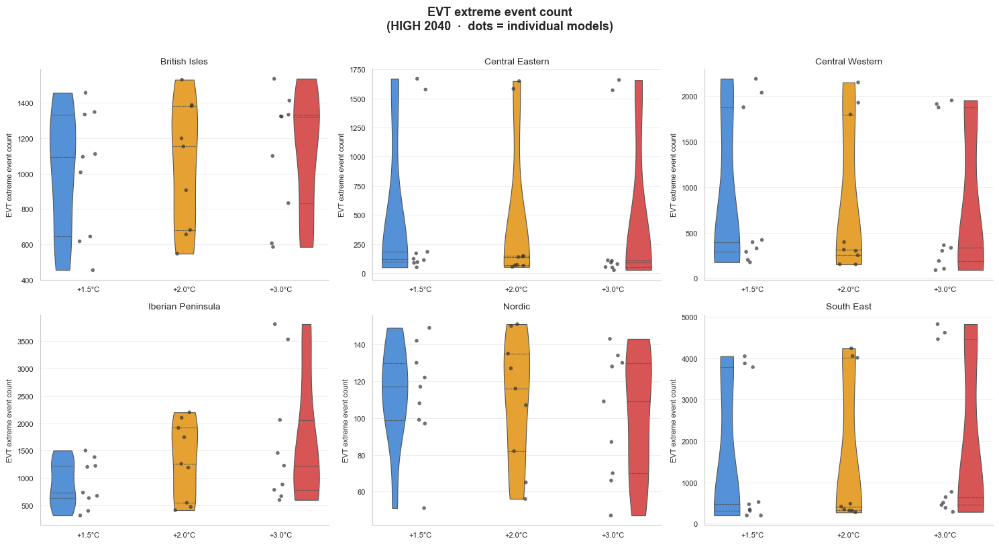

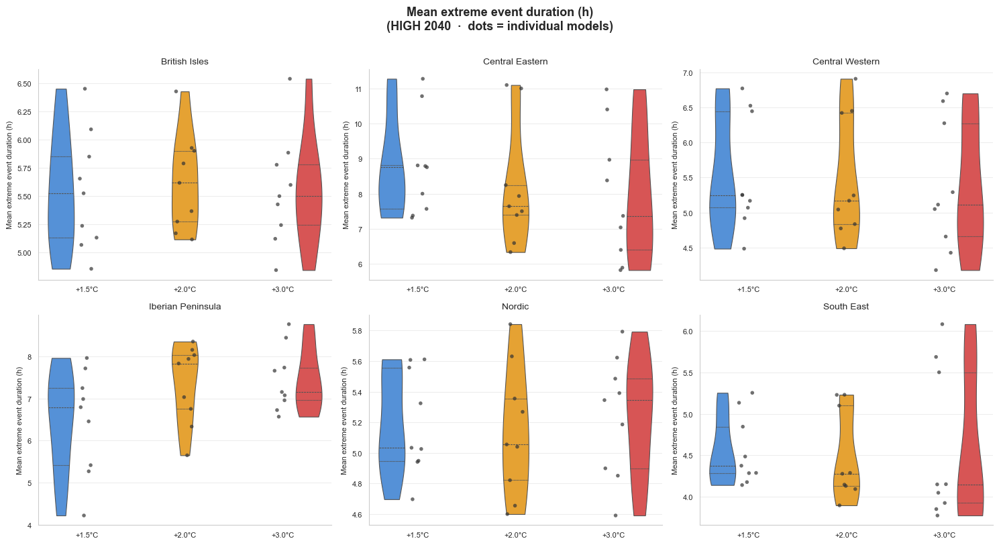

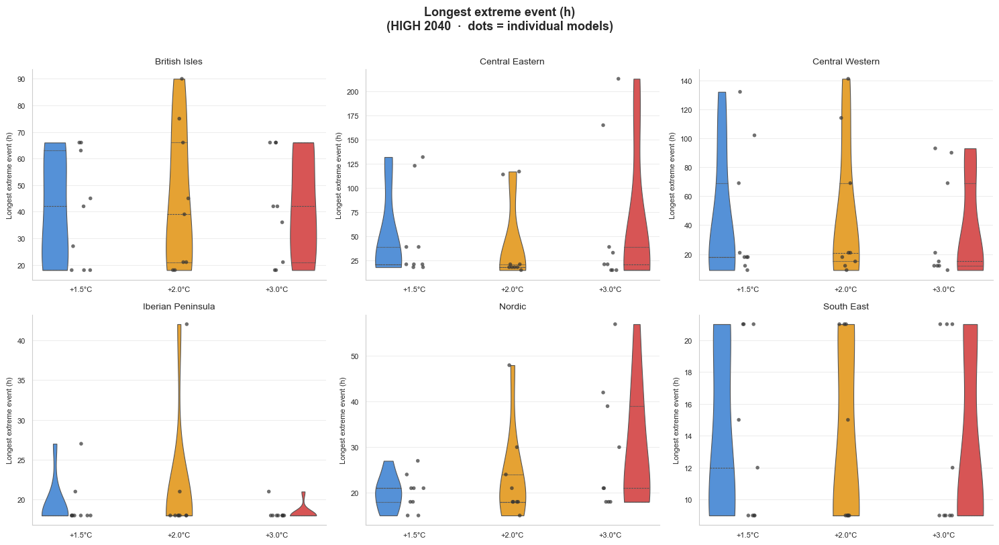

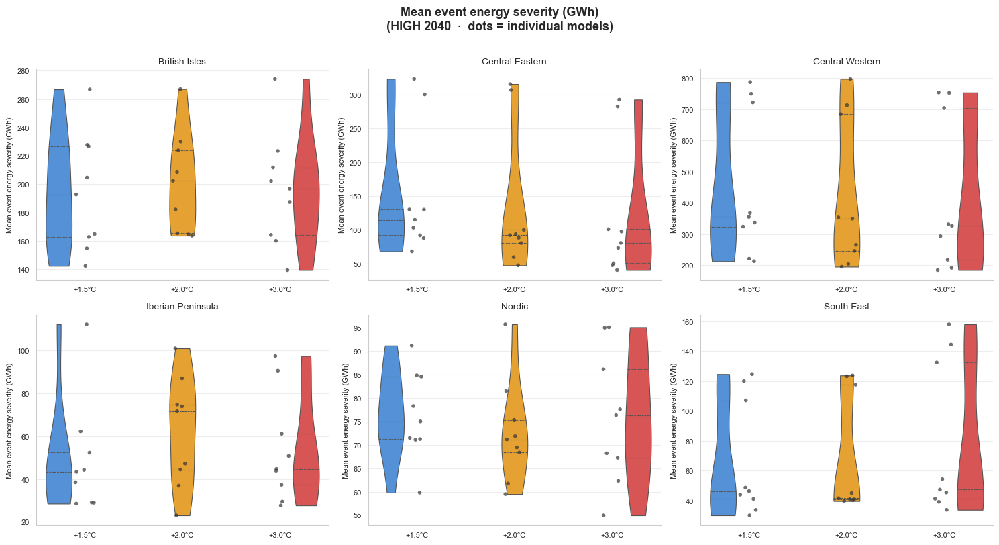

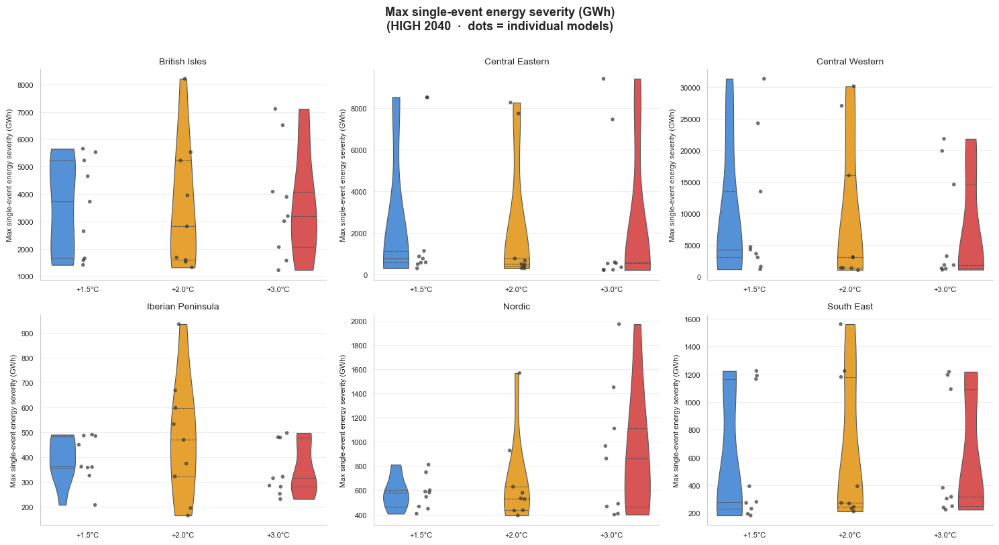

...

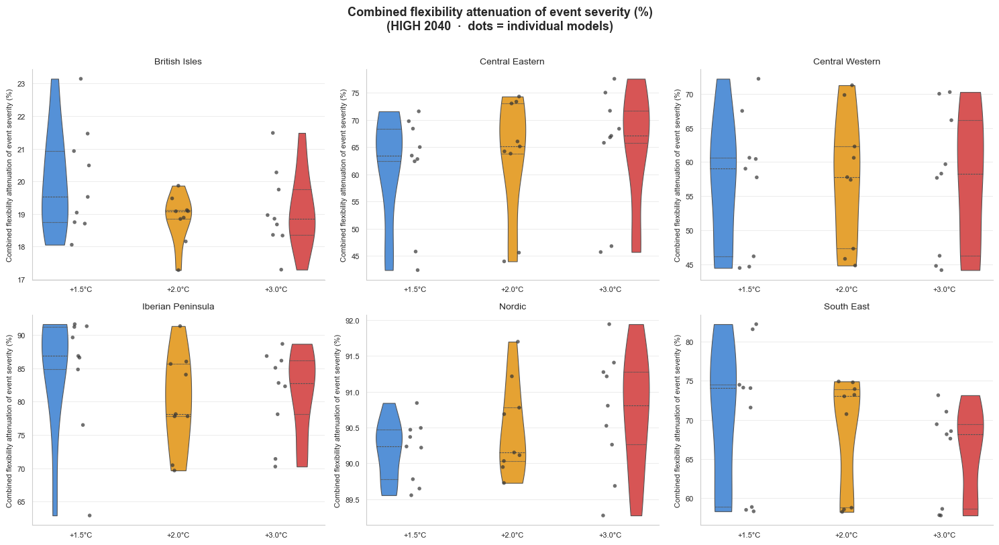

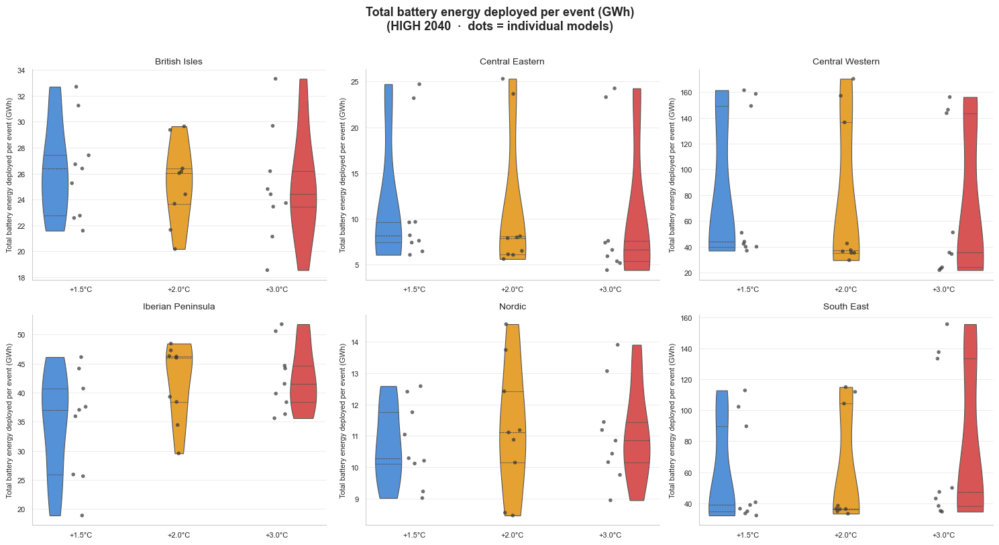

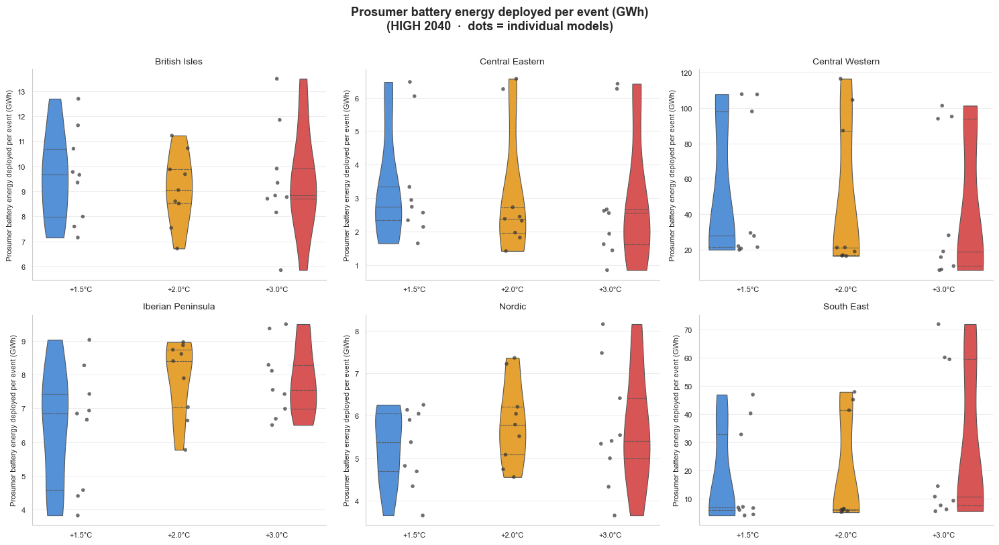

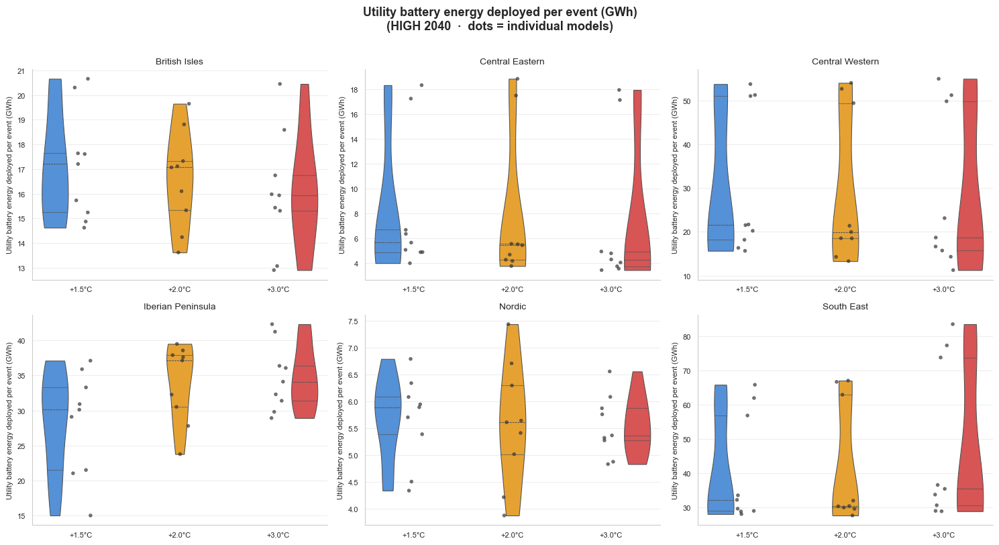

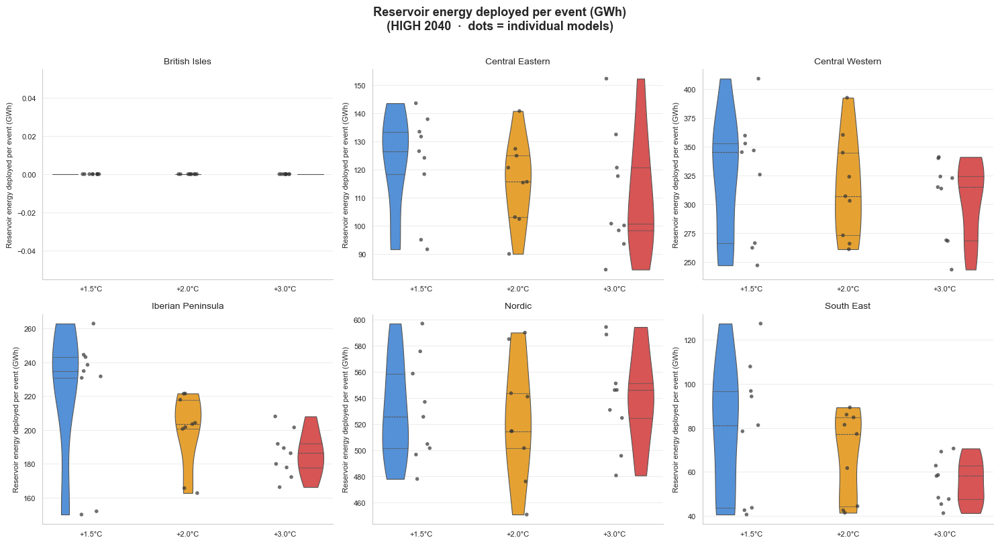

In [49]:
violin_metrics = [
    ("Frequency", "EVT extreme event count", df_ens_extreme),
    ("Avg_Duration_Hours", "Mean extreme event duration (h)", df_ens_extreme),
    ("Max_Duration_Hours", "Longest extreme event (h)", df_ens_extreme),
    ("Avg_Energy_Severity_GWh", "Mean event energy severity (GWh)", df_ens_extreme),
    (
        "Max_Single_Event_Severity_GWh",
        "Max single-event energy severity (GWh)",
        df_ens_extreme,
    ),
    (
        "Avg_PCIT_During_Events_GW",
        "Mean coincident cross-border traffic (GW)",
        df_ens_extreme,
    ),
    (
        "Max_PCIT_During_Events_GW",
        "Max coincident cross-border traffic (GW)",
        df_ens_extreme,
    ),
    (
        "Avg_Net_System_Residual_Load_During_Events_GW",
        "Mean net system residual load during events (GW)",
        df_ens_extreme,
    ),
    (
        "Max_Net_System_Residual_Load_During_Events_GW",
        "Max net system residual load during events (GW)",
        df_ens_extreme,
    ),
    (
        "P90_Annual_Energy_Severity_GWh",
        "P90 annual unmet energy — design year (GWh)",
        df_ens_extreme,
    ),
    (
        "Std_Annual_Energy_Severity_GWh",
        "Std of annual unmet energy — year-to-year variability (GWh)",
        df_ens_extreme,
    ),
    (
        "Total_Annual_Energy_Severity_GWh",
        "Annual unmet energy — baseline (GWh)",
        df_ens_baseline,
    ),
    (
        "Mean_USE_pct",
        "Mean annual unserved energy share (%)",
        df_ens_extreme,
    ),
    (
        "Max_USE_pct",
        "Worst-year unserved energy share (%)",
        df_ens_extreme,
    ),
    # ── Flexibility attenuation ───────────────────────────────────────────────
    (
        "battery_attenuation_pct",
        "Total battery attenuation of event severity (%)",
        df_ens_extreme,
    ),
    (
        "prosumer_attenuation_pct",
        "Prosumer battery attenuation of event severity (%)",
        df_ens_extreme,
    ),
    (
        "utility_attenuation_pct",
        "Utility battery attenuation of event severity (%)",
        df_ens_extreme,
    ),
    (
        "reservoir_attenuation_pct",
        "Reservoir attenuation of event severity (%)",
        df_ens_extreme,
    ),
    (
        "combined_attenuation_pct",
        "Combined flexibility attenuation of event severity (%)",
        df_ens_extreme,
    ),
    # ── Flexibility deployed ──────────────────────────────────────────────────
    (
        "battery_deployed_gwh_per_event",
        "Total battery energy deployed per event (GWh)",
        df_ens_extreme,
    ),
    (
        "prosumer_deployed_gwh_per_event",
        "Prosumer battery energy deployed per event (GWh)",
        df_ens_extreme,
    ),
    (
        "utility_deployed_gwh_per_event",
        "Utility battery energy deployed per event (GWh)",
        df_ens_extreme,
    ),
    (
        "reservoir_deployed_gwh_per_event",
        "Reservoir energy deployed per event (GWh)",
        df_ens_extreme,
    ),
]

for metric, ylabel, df in violin_metrics:
    plot_violin_grid(
        df,
        metric=metric,
        ylabel=ylabel,
        title=f"{ylabel}\n({supply_scenario} {supply_year}  ·  dots = individual models)",
        period_defs=period_defs,
        zones=zones,
        period_colors=period_colors,
    )

In [50]:
(
    df_ens_baseline[df_ens_baseline["Period"] == "+2.0°C"]
    .groupby("model")["Total_Annual_Energy_Severity_GWh"]
    .sum()
    * 1e-3
)

model
CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1          2319.346885
CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1                2401.353627
CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1               2491.746245
CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1                  2409.478955
MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1    2446.389274
MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1          2424.598267
MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1          2524.423538
MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1         2541.272037
MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1            2539.221574
Name: Total_Annual_Energy_Severity_GWh, dtype: float64

## EVT threshold heatmap — inter-model spread

The heatmap shows the model-specific EVT threshold calibrated on each model's
reference-period residual load. Rows are models; columns are zones.
Values in GWh (per 3-hour interval). Spread across rows indicates how much the
choice of model affects what is considered an "extreme" event.

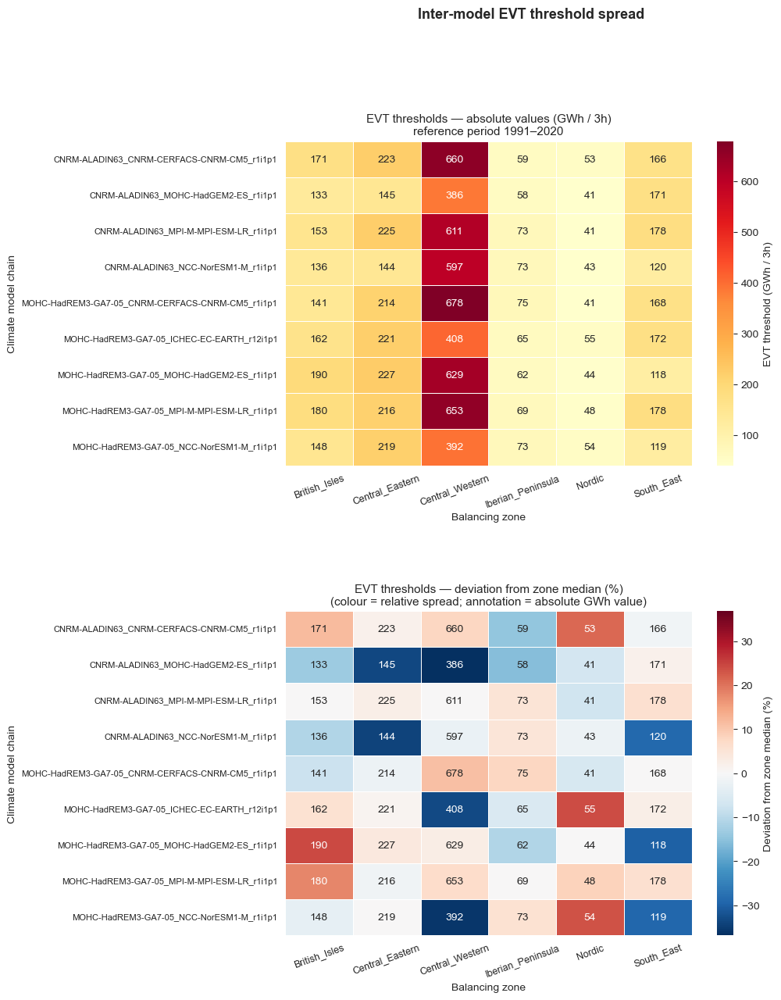


Zone medians (GWh):
British_Isles        153.0
Central_Eastern      218.9
Central_Western      611.3
Iberian_Peninsula     69.3
Nordic                44.0
South_East           168.3

Inter-model spread — IQR (GWh):
British_Isles         29.7
Central_Eastern        9.1
Central_Western      245.8
Iberian_Peninsula     11.1
Nordic                12.0
South_East            52.8

Inter-model spread — IQR / median (%):
British_Isles        19.4
Central_Eastern       4.1
Central_Western      40.2
Iberian_Peninsula    16.1
Nordic               27.3
South_East           31.3


In [51]:
plot_evt_threshold_heatmap(
    evt_thresholds,
    zones=zones,
    models=models,
    reference_period=REFERENCE_PERIOD,
)

# Summary statistics
thr_matrix = pd.DataFrame(
    {
        model: {str(z): float(evt_thresholds[model].sel(zone=z).values) for z in zones}
        for model in models
    }
).T
zone_medians = thr_matrix.median(axis=0)
iqr = thr_matrix.quantile(0.75) - thr_matrix.quantile(0.25)

print("\nZone medians (GWh):")
print(zone_medians.round(1).to_string())
print("\nInter-model spread — IQR (GWh):")
print(iqr.round(1).to_string())
print("\nInter-model spread — IQR / median (%):")
print((iqr / zone_medians * 100).round(1).to_string())

## Climate driver attribution — ensemble view

Stacked-bar charts showing the **ensemble-median attribution** (share of extreme-event
energy anomaly attributable to each driver) for each zone and period.
Individual model values are overlaid as dots so disagreement is immediately visible.

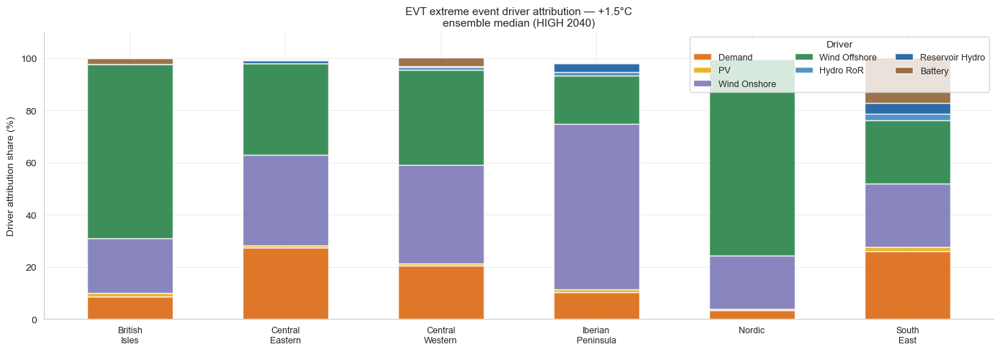

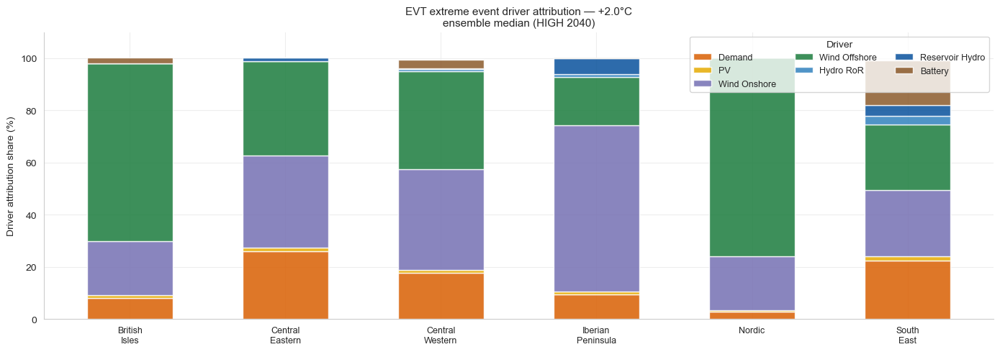

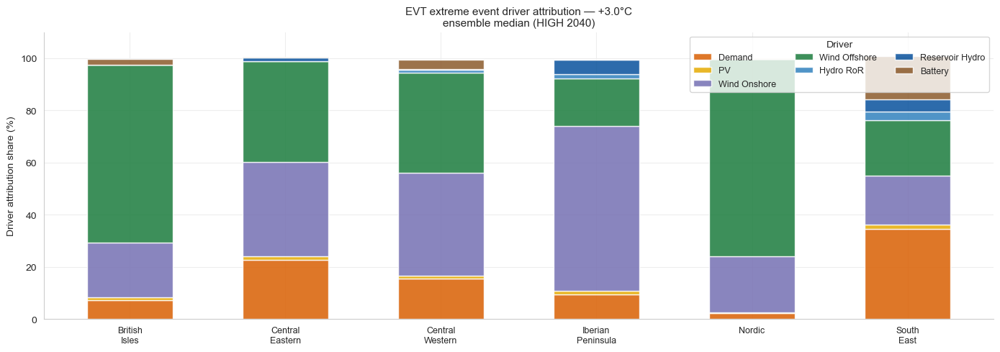

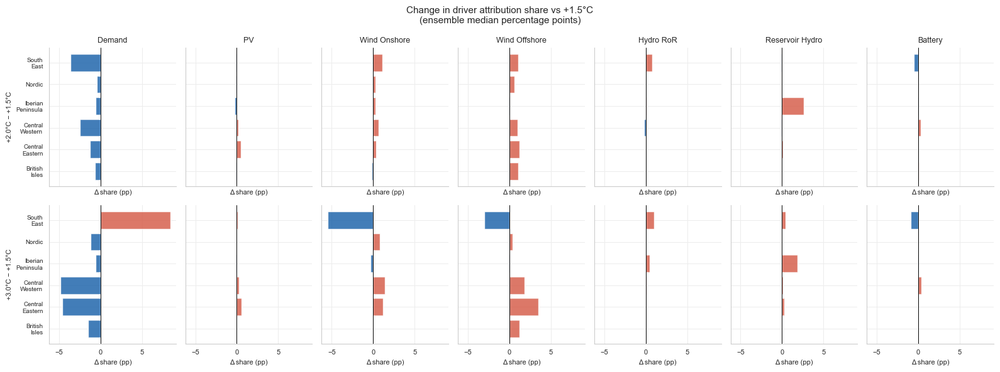

In [52]:
plot_attribution_stacked_bars(
    df_ens_extreme,
    zones=zones,
    period_defs=period_defs,
    driver_cols=driver_cols,
    driver_palette=driver_palette,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)

plot_attribution_change_bars(
    df_ens_extreme,
    zones=zones,
    period_defs=period_defs,
    driver_cols=driver_cols,
)

## Absolute driver anomaly distributions

Box + strip plots showing the **mean absolute energy anomaly per EVT event** (GWh) for each
driver component: demand (higher than seasonal expectation) and each generation / flexibility
type (lower than seasonal expectation).

Boxes span the inter-quartile range; whiskers cover the 10–90th percentile; dots are individual
models. This view complements the percentage-share attribution above by showing raw magnitudes.

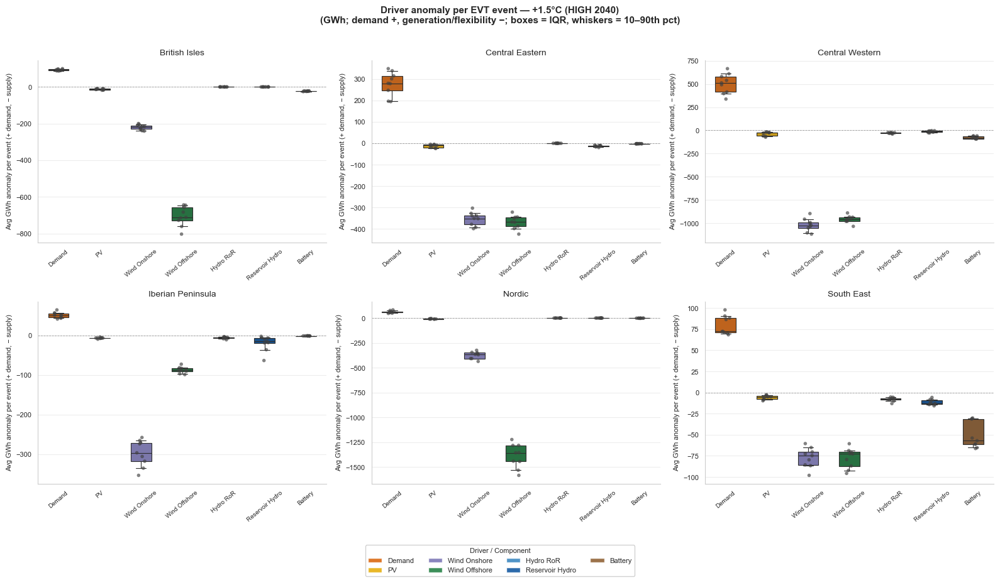

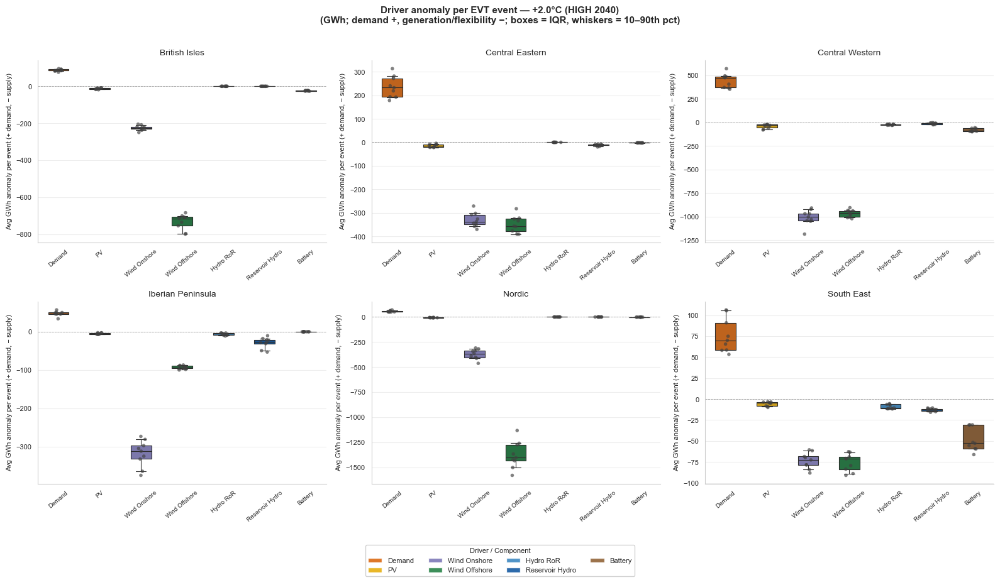

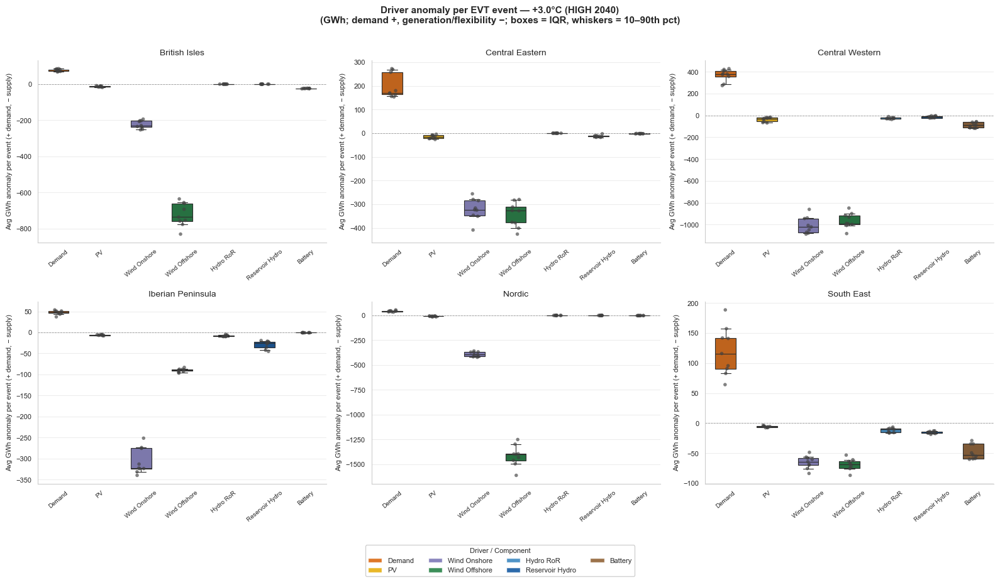

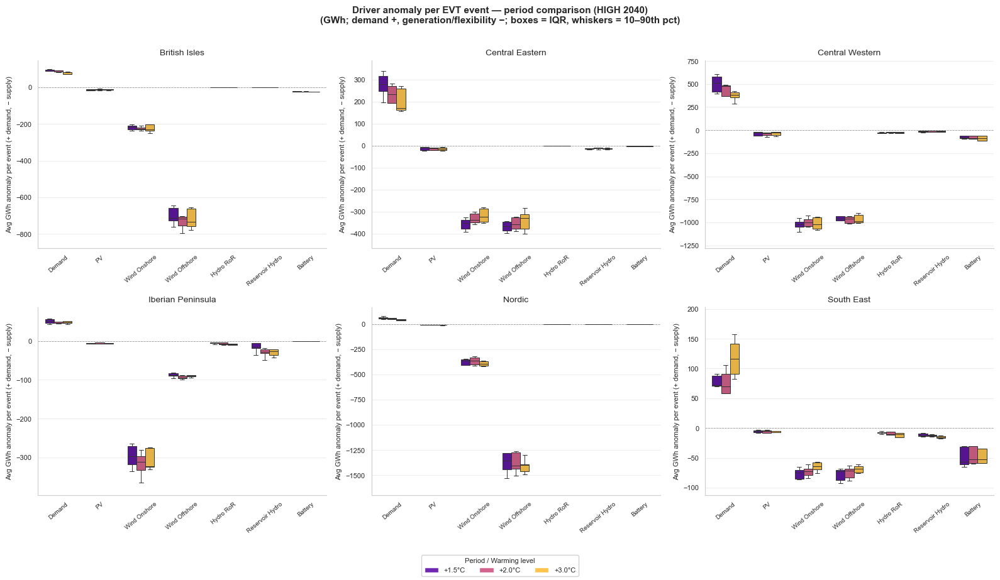

In [56]:
plot_component_anomaly_distributions(
    df_ens_extreme,
    zones=zones,
    period_defs=period_defs,
    component_cols=anomaly_component_cols,
    component_palette=driver_palette,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)

## Compound event co-occurrence

Fraction of Zone A exceedance timesteps that co-occur with a Zone B exceedance
within a ±72 h window (24 steps at 3 h resolution).

df_coo: (972, 5)


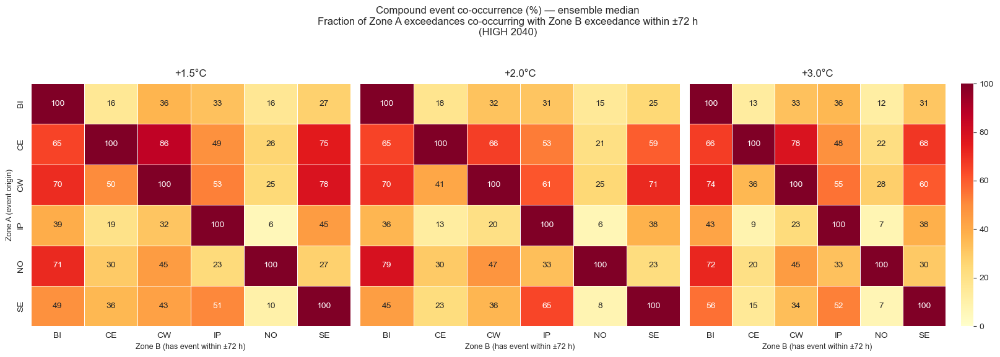

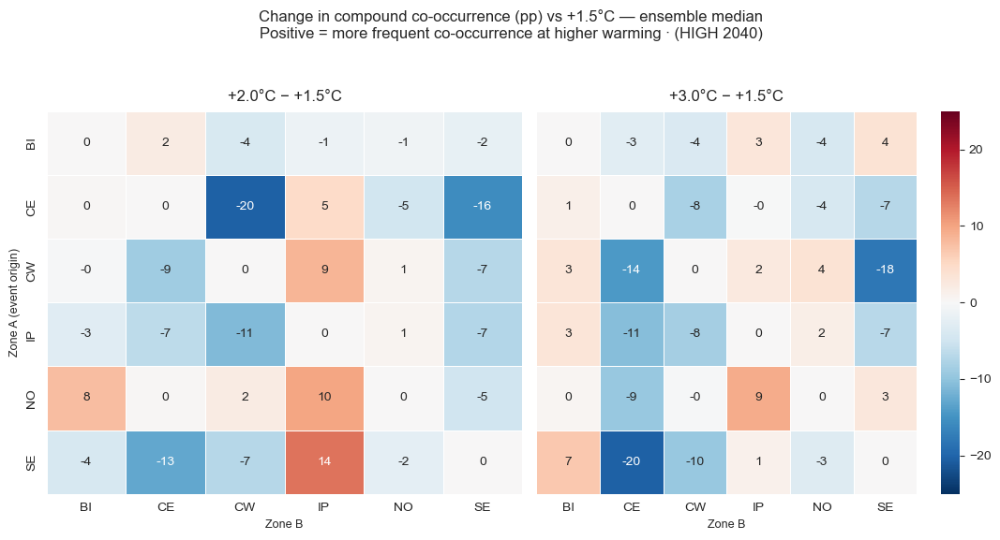

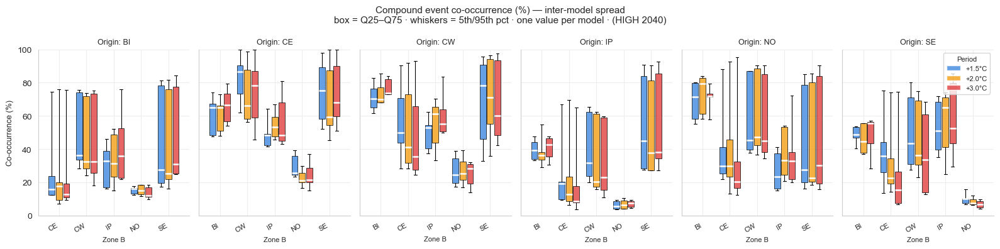

In [54]:
df_coo = compute_zone_pair_cooccurrence(
    _cache_rl, evt_thresholds, period_defs, models, zones
)
print(f"df_coo: {df_coo.shape}")

plot_zone_cooccurrence_heatmaps(
    df_coo,
    zones=zones,
    period_defs=period_defs,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)

plot_zone_cooccurrence_boxplots(
    df_coo,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
    figsize=(16, 4),
)

## Duration–severity scaling

Power-law fit S = a · D^b for individual EVT events pooled across all models.

Extracted 145,820 individual EVT events


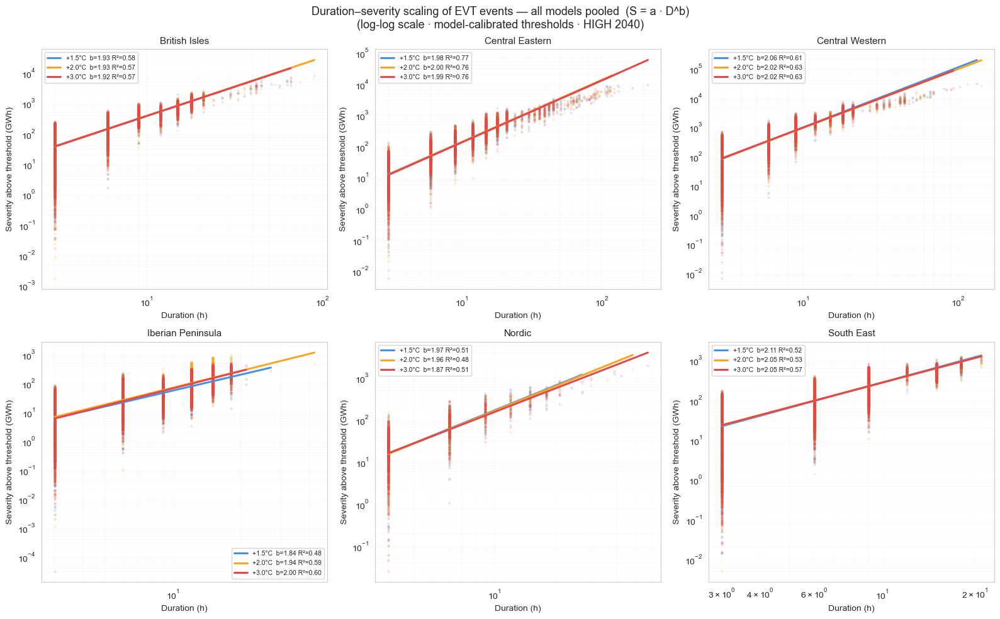


Power-law fit summary (pooled across all models):
                          b_exponent     R2  n_events
zone              period                             
British_Isles     +1.5°C       1.932  0.576      9067
                  +2.0°C       1.933  0.571      9442
                  +3.0°C       1.919  0.565     10052
Central_Eastern   +1.5°C       1.978  0.770      4072
                  +2.0°C       1.998  0.762      3922
                  +3.0°C       1.994  0.756      3747
Central_Western   +1.5°C       2.064  0.610      7923
                  +2.0°C       2.017  0.631      7451
                  +3.0°C       2.016  0.631      7127
Iberian_Peninsula +1.5°C       1.839  0.478      8061
                  +2.0°C       1.945  0.593     11845
                  +3.0°C       1.998  0.602     15020
Nordic            +1.5°C       1.968  0.508      1015
                  +2.0°C       1.959  0.480       989
                  +3.0°C       1.873  0.513       914
South_East        +1.5°C       

In [55]:
df_ds = extract_evt_duration_severity_records(
    _cache_rl, evt_thresholds, period_defs, models, zones
)
print(f"Extracted {len(df_ds):,} individual EVT events")

plot_duration_severity_scaling(
    df_ds,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)